In [1]:
import pandas as pd
from statsbombpy import sb

# 1. Cargamos los eventos de la Final del Mundial (match_id: 3869685)
match_id = 3869685
df_eventos = sb.events(match_id=match_id)

# 2. Filtrar solo los eventos de tipo "Shot" (Tiros)
tiros = df_eventos[df_eventos['type'] == 'Shot'].copy()

# 3. Seleccionar las columnas clave que nos interesan
# Extraemos: Jugador, Equipo, Minuto, Resultado del tiro y el valor de xG
columnas_interes = ['player', 'team', 'minute', 'shot_outcome', 'shot_statsbomb_xg']
tiros_resumen = tiros[columnas_interes].sort_values(by='shot_statsbomb_xg', ascending=False)

# Mostrar los 5 tiros con mayor probabilidad de gol (xG más alto)
tiros_resumen.head()

c:\Users\fabio\AppData\Local\Programs\Python\Python315\Lib\site-packages\statsbombpy\api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


,player,team,minute,shot_outcome,shot_statsbomb_xg
4210,Lionel Andrés Messi Cuccittini,Argentina,22,Goal,0.7835
4241,Aurélien Djani Tchouaméni,France,123,Off T,0.7835
4240,Paulo Bruno Exequiel Dybala,Argentina,122,Goal,0.7835
4239,Kingsley Coman,France,121,Saved,0.7835
4238,Lionel Andrés Messi Cuccittini,Argentina,121,Goal,0.7835


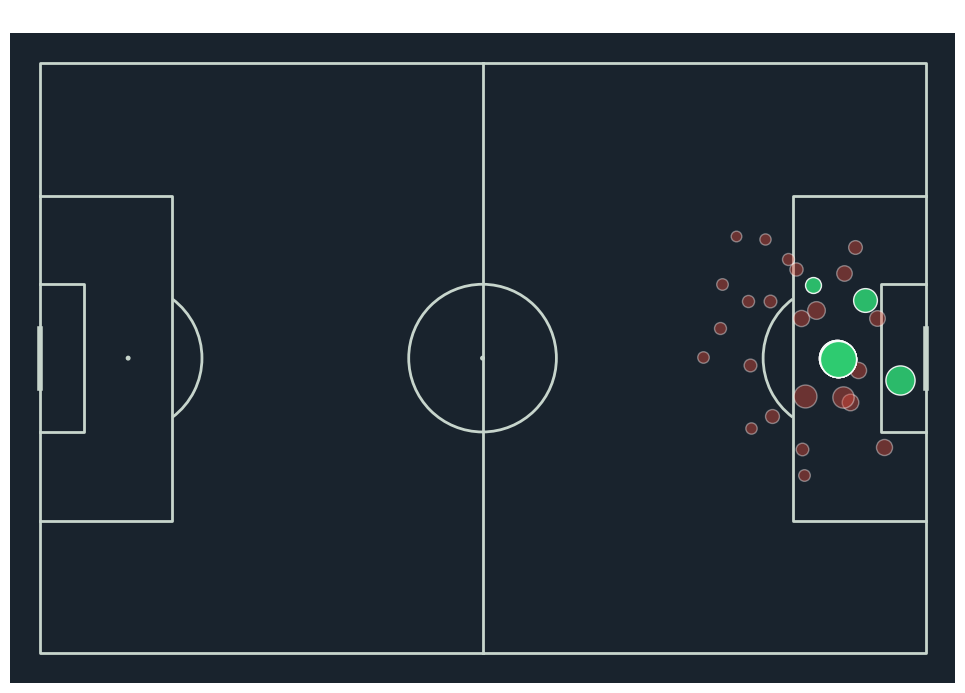

In [2]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# 1. Creamos la cancha de StatsBomb orientada horizontalmente
cancha = Pitch(pitch_type='statsbomb', pitch_color='#19232d', line_color='#c7d5cc')
fig, ax = cancha.draw(figsize=(10, 7))

# 2. Recorremos cada tiro para dibujarlo individualmente
for _, tiro in tiros.iterrows():
    # Extraemos coordenadas X e Y de origen del tiro
    x_tiro = tiro['location'][0]
    y_tiro = tiro['location'][1]
    
    # Asignamos color según el resultado (Gol = Verde, Otro = Rojo/Opaco)
    es_gol = tiro['shot_outcome'] == 'Goal'
    color = '#2ecc71' if es_gol else '#e74c3c'
    alpha = 0.9 if es_gol else 0.4
    
    # Escalamos el tamaño del punto según su valor de xG
    xg_val = tiro['shot_statsbomb_xg']
    tamano = xg_val * 800 + 50 # Multiplicamos para que sea visualmente claro
    
    # Dibujamos el punto del remate
    cancha.scatter(x_tiro, y_tiro, s=tamano, color=color, alpha=alpha, edgecolors='white', ax=ax)

plt.title("🥅 Mapa de Tiros (Shot Map) - Argentina vs Francia", color='white', fontsize=14)
plt.show()

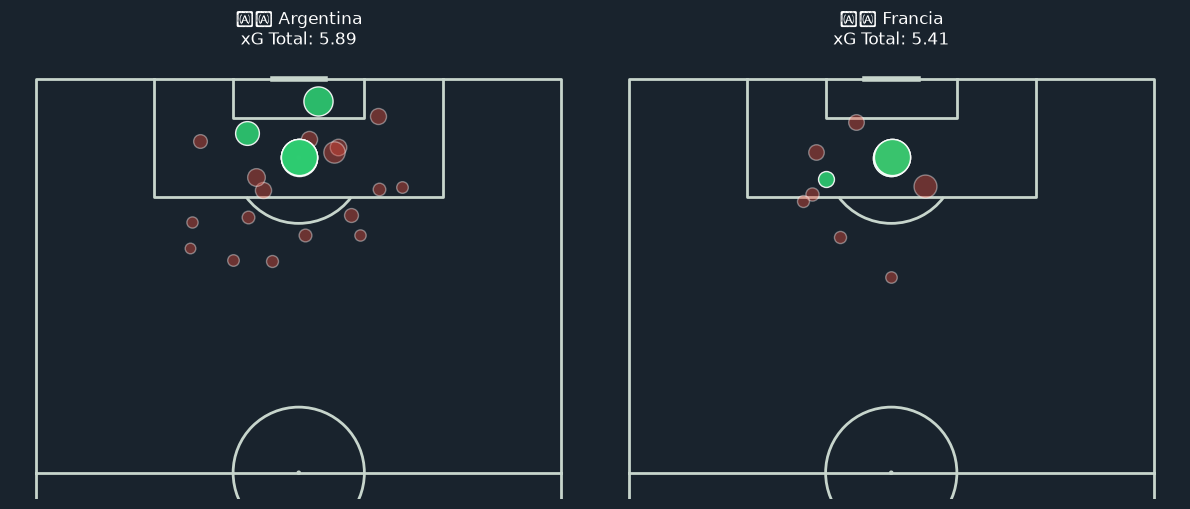

In [3]:
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

# 1. Usamos VerticalPitch (cancha vertical) y half=True para mostrar solo la mitad de ataque
cancha_media = VerticalPitch(pitch_type='statsbomb', half=True, pitch_color='#19232d', line_color='#c7d5cc')
fig, (ax_arg, ax_fra) = plt.subplots(1, 2, figsize=(12, 6), facecolor='#19232d')

# Función para dibujar los tiros de un equipo en un eje (ax)
def dibujar_tiros_equipo(df_tiros, equipo, ax_target, titulo):
    cancha_media.draw(ax=ax_target)
    tiros_eq = df_tiros[df_tiros['team'] == equipo]
    
    for _, tiro in tiros_eq.iterrows():
        x_tiro, y_tiro = tiro['location'][0], tiro['location'][1]
        es_gol = tiro['shot_outcome'] == 'Goal'
        color = '#2ecc71' if es_gol else '#e74c3c'
        alpha = 0.9 if es_gol else 0.4
        tamano = tiro['shot_statsbomb_xg'] * 800 + 50
        
        cancha_media.scatter(x_tiro, y_tiro, s=tamano, color=color, alpha=alpha, edgecolors='white', ax=ax_target)
    
    # Calcular xG Total del equipo
    xg_total = tiros_eq['shot_statsbomb_xg'].sum()
    ax_target.set_title(f"{titulo}\nxG Total: {xg_total:.2f}", color='white', fontsize=12)

# Dibujamos ambos equipos lado a lado
dibujar_tiros_equipo(tiros, 'Argentina', ax_arg, "🇦🇷 Argentina")
dibujar_tiros_equipo(tiros, 'France', ax_fra, "🇫🇷 Francia")

plt.tight_layout()
plt.show()

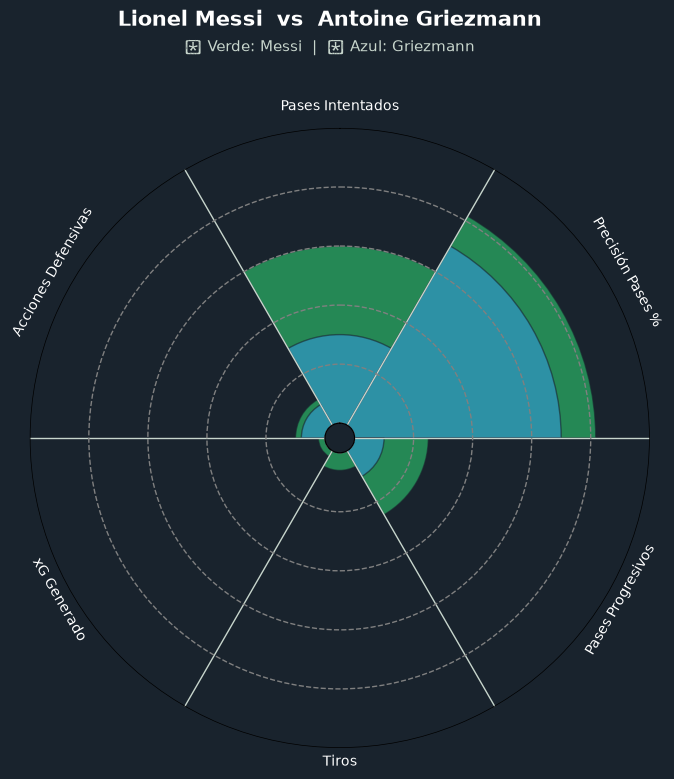

,Métrica,Lionel Messi,Antoine Griezmann
0,Pases Intentados,60.00,30.0
1,Precisión Pases %,81.70,70.0
2,Pases Progresivos,25.00,10.0
3,Tiros,6.00,0.0
4,xG Generado,2.24,0.0
5,Acciones Defensivas,10.00,8.0


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import PyPizza
from statsbombpy import sb

# 1. Cargamos el partido
df_eventos = sb.events(match_id=3869685)

# 2. Función auxiliar para calcular métricas de un jugador en este partido
def obtener_metrics_jugador(nombre):
    df_j = df_eventos[df_eventos['player'] == nombre]
    
    # Pases
    pases = df_j[df_j['type'] == 'Pass']
    total_pases = len(pases)
    p_comp = len(pases[pases['pass_outcome'].isna()])
    prec_pases = (p_comp / total_pases * 100) if total_pases > 0 else 0
    
    pases_prog = 0
    for _, p in pases.iterrows():
        if (p['pass_end_location'][0] - p['location'][0]) >= 10:
            pases_prog += 1
            
    # Tiros / xG
    tiros = df_j[df_j['type'] == 'Shot']
    total_tiros = len(tiros)
    xg_total = tiros['shot_statsbomb_xg'].sum() if total_tiros > 0 else 0
    
    # Recuperaciones / Entradas
    defensivas = len(df_j[df_j['type'].isin(['Duel', 'Interception', 'Ball Recovery'])])
    
    return [total_pases, round(prec_pases, 1), pases_prog, total_tiros, round(xg_total, 2), defensivas]

# 3. Parámetros y Valores
params = ["Pases Intentados", "Precisión Pases %", "Pases Progresivos", "Tiros", "xG Generado", "Acciones Defensivas"]
val_messi = obtener_metrics_jugador('Lionel Andrés Messi Cuccittini')
val_griezmann = obtener_metrics_jugador('Antoine Griezmann')

# 4. Configurar el gráfico de Radar
baker = PyPizza(
    params=params,
    background_color="#19232d",
    straight_line_color="#c7d5cc",
    straight_line_lw=1,
    last_circle_lw=1,
    other_circle_lw=1,
    inner_circle_size=5
)

fig, ax = baker.make_pizza(
    val_messi,
    compare_values=val_griezmann,
    figsize=(8, 8.5),
    param_location=106,
    kwargs_slices=dict(facecolor="#2ecc71", edgecolor="#19232d", linewidth=1, alpha=0.6),
    kwargs_compare=dict(facecolor="#3498db", edgecolor="#19232d", linewidth=1, alpha=0.6),
    kwargs_params=dict(color="white", fontsize=10),
    kwargs_values=dict(alpha=0),         # Oculta los números de Messi volviéndolos transparentes
    kwargs_compare_values=dict(alpha=0)  # Oculta los números de Griezmann volviéndolos transparentes
)

# Título y Leyenda arriba
fig.text(0.5, 0.98, "Lionel Messi  vs  Antoine Griezmann", size=15, ha="center", color="white", weight="bold")
fig.text(0.5, 0.95, "🟩 Verde: Messi  |  🟦 Azul: Griezmann", size=11, ha="center", color="#c7d5cc")

plt.show()

# 5. Tabla comparativa clara para acompañar el gráfico
df_comparativa = pd.DataFrame({
    'Métrica': params,
    'Lionel Messi': val_messi,
    'Antoine Griezmann': val_griezmann
})
df_comparativa